
THỰC HÀNH XÂY DỰNG MÔ HÌNH HỒI QUY TUYẾN TÍNH

Bài toán

Bài 1: Khám phá 3 feature: bmi, bp và s5.
Bài 2: So sánh Linear Regression với các bộ feature khác nhau.
Bài 3: So sánh các thuật toán hồi quy.

                                       
                                    Phần 1: Nạp dữ liệu & Khám phá 3 đặc trưng trọng tâm

Mục tiêu: Kiểm tra chất lượng dữ liệu, phân phối thống kê và mức độ tương quan tuyến tính của 3 biến đầu vào quan trọng nhất với biến mục tiêu target

Số giá trị thiếu:
 bmi       0
bp        0
s5        0
target    0
dtype: int64

Thống kê mô tả:
             bmi        bp        s5    target
count  442.0000  442.0000  442.0000  442.0000
mean    -0.0000   -0.0000    0.0000  152.1335
std      0.0476    0.0476    0.0476   77.0930
min     -0.0903   -0.1124   -0.1261   25.0000
25%     -0.0342   -0.0367   -0.0332   87.0000
50%     -0.0073   -0.0057   -0.0019  140.5000
75%      0.0312    0.0356    0.0324  211.5000
max      0.1706    0.1320    0.1336  346.0000

Ma trận tương quan:
            bmi      bp      s5  target
bmi     1.0000  0.3954  0.4462  0.5865
bp      0.3954  1.0000  0.3935  0.4415
s5      0.4462  0.3935  1.0000  0.5659
target  0.5865  0.4415  0.5659  1.0000


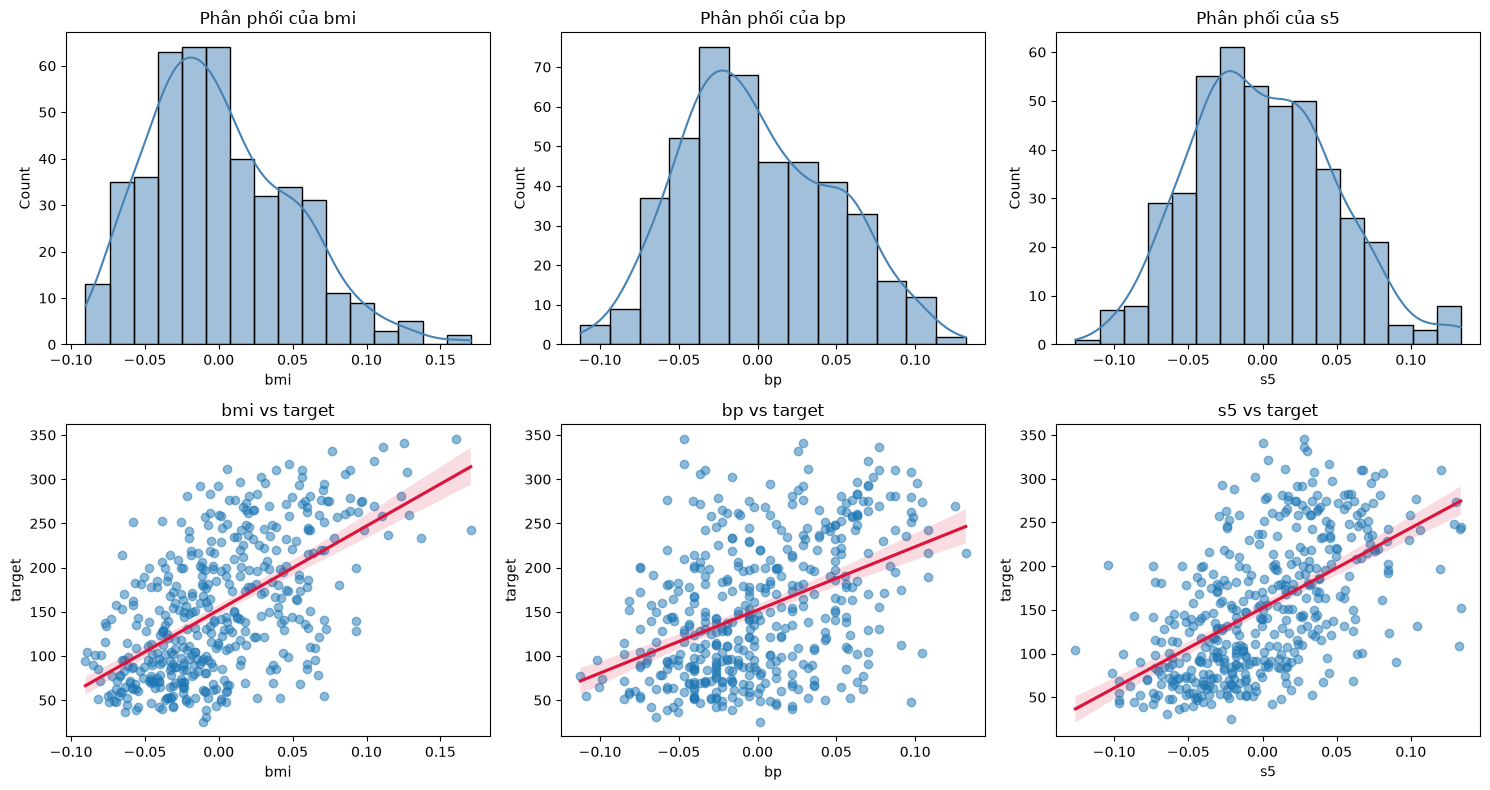

In [17]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes


diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

features_3 = ['bmi', 'bp', 's5']
sub_df = df[features_3 + ['target']]

print("Số giá trị thiếu:\n", sub_df.isnull().sum())
print("\nThống kê mô tả:\n", sub_df.describe().round(4))
print("\nMa trận tương quan:\n", sub_df.corr().round(4))


fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(features_3):
    sns.histplot(df[col], kde=True, ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'Phân phối của {col}')
    
    sns.regplot(x=df[col], y=df['target'], ax=axes[1, i],
                scatter_kws={'alpha': 0.5}, line_kws={'color': 'crimson'})
    axes[1, i].set_title(f'{col} vs target')

plt.tight_layout()
plt.show()

bmi: Phân phối lệch phải, các giá trị tập trung chủ yếu trong khoảng −0.05 đến 0.05. Đuôi bên phải kéo dài đến khoảng 0.17, cho thấy có một số mẫu mang giá trị BMI chuẩn hóa cao.

bp: Phân phối hơi lệch phải, phần lớn giá trị nằm trong khoảng −0.05 đến 0.06. Tần suất cao nhất ở vùng khoảng −0.03; các cột cao thấp không đều.

s5: Phân phối khá cân đối quanh 0, phần lớn giá trị nằm trong khoảng −0.06 đến 0.06. Hai phía có ít mẫu ở xa vùng trung tâm.

                                    Phần 2: Hồi quy tuyến tính đơn biến & đa biến trên 3 đặc trưng

Mục tiêu: Chia tập Train/Test theo tỷ lệ 80/20, so sánh hiệu năng giữa mô hình Hồi quy đơn biến (chỉ dùng bmi) và Hồi quy đa biến (kết hợp cả bmi, bp, s5).

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df.drop(columns=['target'])
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

def evaluate_regression(model, X_tr, X_te, name):
    model.fit(X_tr, y_train)
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)
    return {
        'Mô hình': name,
        'Train R2': round(r2_score(y_train, pred_tr), 4),
        'Test R2': round(r2_score(y_test, pred_te), 4),
        'MAE': round(mean_absolute_error(y_test, pred_te), 2),
        'MSE': round(mean_squared_error(y_test, pred_te), 2),
        'RMSE': round(np.sqrt(mean_squared_error(y_test, pred_te)), 2)
    }

lr_bmi = LinearRegression()
res_bmi = evaluate_regression(lr_bmi, X_train[['bmi']], X_test[['bmi']], 'Đơn biến (bmi)')

lr_3 = LinearRegression()
res_3 = evaluate_regression(lr_3, X_train[features_3], X_test[features_3], 'Đa biến (bmi, bp, s5)')

print(pd.DataFrame([res_bmi, res_3]).to_string(index=False))
print("\nHệ số hồi quy mô hình 3 biến:")
print(f"Intercept: {lr_3.intercept_:.4f}")
for col, coef in zip(features_3, lr_3.coef_):
    print(f"  {col}: {coef:.4f}")

              Mô hình  Train R2  Test R2   MAE     MSE  RMSE
       Đơn biến (bmi)    0.3657   0.2334 52.26 4061.83 63.73
Đa biến (bmi, bp, s5)    0.4831   0.4543 44.29 2891.04 53.77

Hệ số hồi quy mô hình 3 biến:
Intercept: 151.6742
  bmi: 650.6314
  bp: 283.8989
  s5: 491.9827


                                        Phần 3: Hồi quy tuyến tính đa biến trên toàn bộ 10 đặc trưng
Mục tiêu: Đưa toàn bộ 10 đặc trưng vào mô hình để kiểm tra liệu việc dùng hết dữ liệu có cải thiện độ chính xác hay gây ra hiện tượng quá khớp (overfitting) / đa cộng tuyến.

              Mô hình  Train R2  Test R2   MAE     MSE  RMSE
Đa biến (bmi, bp, s5)    0.4831   0.4543 44.29 2891.04 53.77
Đa biến (10 features)    0.5279   0.4526 42.79 2900.19 53.85

Trọng số các đặc trưng:
 Đặc trưng  Hệ số (Weight)
       s1         -931.49
       s5          736.20
      bmi          542.43
       s2          518.06
       bp          347.70
       s4          275.32
      sex         -241.96
       s3          163.42
       s6           48.67
      age           37.90


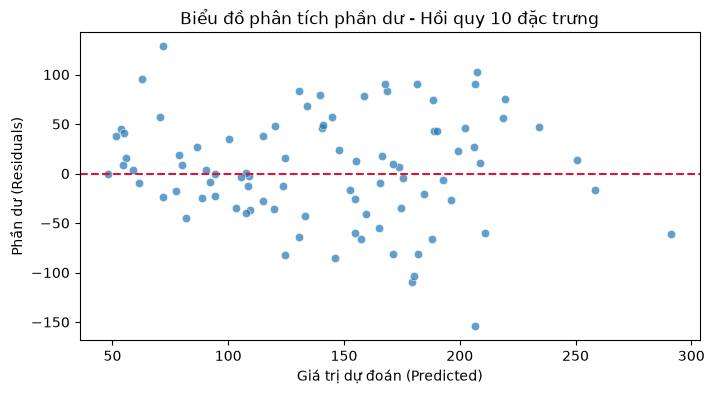

In [19]:

lr_all = LinearRegression()
res_all = evaluate_regression(lr_all, X_train, X_test, 'Đa biến (10 features)')


coef_all = pd.DataFrame({
    'Đặc trưng': X.columns,
    'Hệ số (Weight)': lr_all.coef_.round(2)
}).sort_values(by='Hệ số (Weight)', key=abs, ascending=False)

print(pd.DataFrame([res_3, res_all]).to_string(index=False))
print("\nTrọng số các đặc trưng:\n", coef_all.to_string(index=False))

y_pred_all = lr_all.predict(X_test)
residuals = y_test - y_pred_all

plt.figure(figsize=(8, 4))
sns.scatterplot(x=y_pred_all, y=residuals, alpha=0.7)
plt.axhline(0, color='crimson', linestyle='--')
plt.xlabel('Giá trị dự đoán (Predicted)')
plt.ylabel('Phần dư (Residuals)')
plt.title('Biểu đồ phân tích phần dư - Hồi quy 10 đặc trưng')
plt.show()

                                       Phần 4: Tối ưu hóa mô hình với Hồi quy điều chuẩn (Ridge & Lasso)

Mục tiêu: Sử dụng kỹ thuật điều chuẩn Ridge và  Lasso kết hợp kiểm định chéo 5-fold để xử lý đa cộng tuyến, co giảm trọng số nhiễu và chọn lọc đặc trưng tự động.

In [20]:
from sklearn.linear_model import RidgeCV, LassoCV

alphas = np.logspace(-3, 2, 100)

ridge_cv = RidgeCV(alphas=alphas, cv=5)
res_ridge = evaluate_regression(ridge_cv, X_train, X_test, 'RidgeCV (10 features)')

lasso_cv = LassoCV(alphas=alphas, cv=5, random_state=42)
res_lasso = evaluate_regression(lasso_cv, X_train, X_test, 'LassoCV (10 features)')

summary_df = pd.DataFrame([res_bmi, res_3, res_all, res_ridge, res_lasso])
print("=== BẢNG SO SÁNH TỔNG HỢP ===")
print(summary_df.to_string(index=False))

weights_comp = pd.DataFrame({
    'Đặc trưng': X.columns,
    'LinearRegression': lr_all.coef_.round(2),
    'RidgeCV': ridge_cv.coef_.round(2),
    'LassoCV': lasso_cv.coef_.round(2)
})
print(f"\nAlpha tối ưu - Ridge: {ridge_cv.alpha_:.4f} | Lasso: {lasso_cv.alpha_:.4f}")
print("\n=== SO SÁNH TRỌNG SỐ ===")
print(weights_comp.to_string(index=False))

=== BẢNG SO SÁNH TỔNG HỢP ===
              Mô hình  Train R2  Test R2   MAE     MSE  RMSE
       Đơn biến (bmi)    0.3657   0.2334 52.26 4061.83 63.73
Đa biến (bmi, bp, s5)    0.4831   0.4543 44.29 2891.04 53.77
Đa biến (10 features)    0.5279   0.4526 42.79 2900.19 53.85
RidgeCV (10 features)    0.5210   0.4607 42.98 2857.38 53.45
LassoCV (10 features)    0.5194   0.4713 42.78 2800.96 52.92

Alpha tối ưu - Ridge: 0.0933 | Lasso: 0.0739

=== SO SÁNH TRỌNG SỐ ===
Đặc trưng  LinearRegression  RidgeCV  LassoCV
      age             37.90    42.78     0.00
      sex           -241.96  -207.58  -171.17
      bmi            542.43   508.19   554.41
       bp            347.70   318.69   313.23
       s1           -931.49  -113.34  -105.83
       s2            518.06   -84.77    -0.00
       s3            163.42  -189.34  -236.28
       s4            275.32   152.68     0.00
       s5            736.20   395.90   463.04
       s6             48.67    78.57    38.33


# BÀI 2. SO SÁNH CÁC BỘ FEATURE

**Mục tiêu:** Đánh giá hiệu năng của mô hình **Hồi quy tuyến tính (`LinearRegression`)** khi tăng dần số lượng đặc trưng đầu vào:

 Bộ 1 (1 feature): `['bmi']` — Đặc trưng đơn lẻ có tương quan cao nhất với biến mục tiêu.
 Bộ 2 (3 features):`['bmi', 'bp', 's5']` — Nhóm 3 đặc trưng trọng tâm đã khám phá ở Bài 1.
 Bộ 3 (10 features): Toàn bộ 10 đặc trưng có trong bộ dữ liệu Diabetes.


1. Nạp dữ liệu, chia tập Train/Test và định nghĩa các bộ feature

In [21]:

diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

feature_sets = {
    "Bộ 1: 1 feature (bmi)": ['bmi'],
    "Bộ 2: 3 features (bmi, bp, s5)": ['bmi', 'bp', 's5'],
    "Bộ 3: Toàn bộ 10 features": list(X.columns)
}

print(f"Kích thước tập Train: {X_train.shape}, tập Test: {X_test.shape}")

Kích thước tập Train: (353, 10), tập Test: (89, 10)


2. Huấn luyện và đánh giá mô hình trên từng bộ feature

In [ ]:
results = []

for name, cols in feature_sets.items():
    model = LinearRegression()
    model.fit(X_train[cols], y_train)
    
    y_train_pred = model.predict(X_train[cols])
    y_test_pred = model.predict(X_test[cols])
    
    results.append({
        "Bộ feature": name,
        "Số biến": len(cols),
        "Train R2": round(r2_score(y_train, y_train_pred), 4),
        "Test R2": round(r2_score(y_test, y_test_pred), 4),
        "MAE": round(mean_absolute_error(y_test, y_test_pred), 2),
        "MSE": round(mean_squared_error(y_test, y_test_pred), 2),
        "RMSE": round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 2)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Bộ feature,Số biến,Train R2,Test R2,MAE,MSE,RMSE
0,Bộ 1: 1 feature (bmi),1,0.3657,0.2334,52.26,4061.83,63.73
1,"Bộ 2: 3 features (bmi, bp, s5)",3,0.4831,0.4543,44.29,2891.04,53.77
2,Bộ 3: Toàn bộ 10 features,10,0.5279,0.4526,42.79,2900.19,53.85


3. Trực quan hóa so sánh và nhận xét

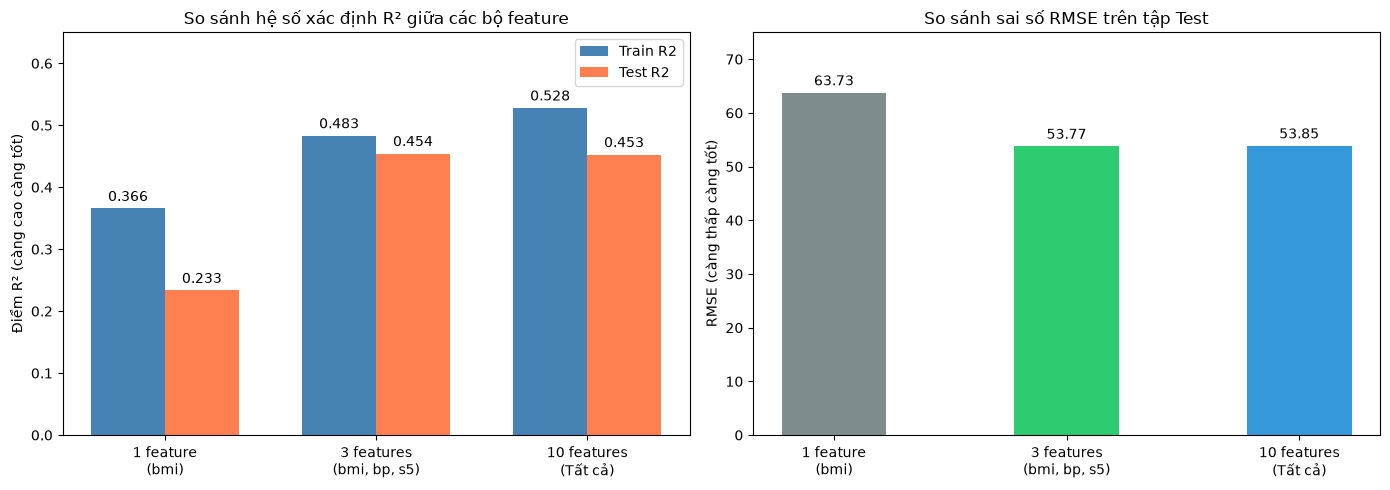

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

labels = ['1 feature\n(bmi)', '3 features\n(bmi, bp, s5)', '10 features\n(Tất cả)']
x = np.arange(len(labels))
width = 0.35

rects1 = axes[0].bar(x - width/2, results_df['Train R2'], width, label='Train R2', color='steelblue')
rects2 = axes[0].bar(x + width/2, results_df['Test R2'], width, label='Test R2', color='coral')
axes[0].set_title('So sánh hệ số xác định R² giữa các bộ feature')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylim(0, 0.65)
axes[0].set_ylabel('Điểm R² (càng cao càng tốt)')
axes[0].legend()
axes[0].bar_label(rects1, padding=3, fmt='%.3f')
axes[0].bar_label(rects2, padding=3, fmt='%.3f')

rects3 = axes[1].bar(labels, results_df['RMSE'], width=0.45, color=['#7f8c8d', '#2ecc71', '#3498db'])
axes[1].set_title('So sánh sai số RMSE trên tập Test')
axes[1].set_ylim(0, 75)
axes[1].set_ylabel('RMSE (càng thấp càng tốt)')
axes[1].bar_label(rects3, padding=3, fmt='%.2f')

plt.tight_layout()
plt.show()

### Nhận xét kết quả so sánh:

1. Từ 1 feature lên 3 features (Bước nhảy vọt về hiệu năng):
   + Khi chỉ dùng duy nhất `bmi`, mô hình bị thiếu thông tin (*underfitting*), chỉ đạt $Test\ R^2 = 0.2334$ và sai số $RMSE = 63.73$.
   + Khi bổ sung thêm `bp` và `s5`, $Test\ R^2$ tăng gần gấp đôi lên **$0.4543$**, đồng thời $RMSE$ giảm mạnh gần 10 đơn vị xuống **$53.77$**.

2. Từ 3 features lên 10 features (Hiệu suất bão hòa & bắt đầu quá khớp nhẹ):
   * Dù điểm $Train\ R^2$ tiếp tục tăng từ $0.4831$ lên $0.5279$, nhưng điểm $Test\ R^2$ không tăng thêm mà hơi giảm nhẹ (từ $0.4543$ xuống $0.4526$, $RMSE$ tăng từ $53.77$ lên $53.85$).
   * Khoảng cách chênh lệch giữa $Train\ R^2$ và $Test\ R^2$ nới rộng lên $0.0753$ (so với chỉ $0.0288$ ở bộ 3 feature), cho thấy 7 đặc trưng còn lại chứa nhiễu hoặc đa cộng tuyến làm giảm khả năng tổng quát hóa.

3. **Lựa chọn tối ưu:** Bộ **3 features (`bmi`, `bp`, `s5`)** đạt điểm $Test\ R^2$ cao nhất và $RMSE$ thấp nhất trong 3 phương án với mô hình hồi quy tuyến tính thường, đảm bảo sự cân bằng tốt nhất giữa độ chính xác và tính đơn giản của mô hình.


BÀI 3. SO SÁNH CÁC THUẬT TOÁN HỒI QUY

**Mục tiêu:** Đánh giá và so sánh hiệu năng của **7 thuật toán hồi quy** thuộc 3 nhóm phương pháp khác nhau trên cùng tập dữ liệu Diabetes (toàn bộ 10 đặc trưng, chia Train/Test tỷ lệ 80/20):

1. **Nhóm mô hình tuyến tính (Linear Models):**
   * `Linear Regression`: Hồi quy tuyến tính cơ sở (OLS).
   * `Ridge (alpha=0.1)`: Hồi quy tuyến tính với điều chuẩn $L_2$ (giảm hiện tượng đa cộng tuyến).
   * `Lasso (alpha=0.1)`: Hồi quy tuyến tính với điều chuẩn $L_1$ (tự động chọn lọc đặc trưng).
2. **Nhóm mô hình cây & học kết hợp (Tree-based & Ensemble):**
   * `Decision Tree`: Cây quyết định đơn lẻ (`max_depth=4`).
   * `Random Forest`: Rừng ngẫu nhiên kết hợp 100 cây quyết định độc lập (Bagging).
   * `Gradient Boosting`: Tăng cường độ dốc kết hợp tuần tự 100 cây yếu (Boosting).
3. **Nhóm máy vector hỗ trợ (Kernel-based):**
   * `SVR (RBF)`: Support Vector Regression sử dụng nhân phi tuyến RBF (`C=100`).

## 1. Import các thuật toán và khởi tạo danh sách mô hình

In [24]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR


diabetes = load_diabetes(as_frame=True)
df = diabetes.frame
X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=0.1)": Ridge(alpha=0.1),
    "Lasso (alpha=0.1)": Lasso(alpha=0.1),
    "Decision Tree": DecisionTreeRegressor(max_depth=4, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "SVR (RBF)": SVR(kernel='rbf', C=100)
}

print(f"Đã khởi tạo {len(models)} mô hình hồi quy.")

Đã khởi tạo 7 mô hình hồi quy.


## 2. Huấn luyện và tổng hợp kết quả đánh giá

In [27]:
results = []

for name, model in models.items():
  
    model.fit(X_train, y_train)
    
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    results.append({
        "Thuật toán": name,
        "Train R2": round(r2_score(y_train, y_train_pred), 4),
        "Test R2": round(r2_score(y_test, y_test_pred), 4),
        "MAE": round(mean_absolute_error(y_test, y_test_pred), 2),
        "MSE": round(mean_squared_error(y_test, y_test_pred), 2),
        "RMSE": round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 2)
    })

results_df = pd.DataFrame(results).sort_values(by="Test R2", ascending=False).reset_index(drop=True)
display(results_df)

,Thuật toán,Train R2,Test R2,MAE,MSE,RMSE
0,SVR (RBF),0.6681,0.5087,39.39,2602.87,51.02
1,Lasso (alpha=0.1),0.5169,0.4719,42.85,2798.19,52.90
2,Ridge (alpha=0.1),0.5206,0.4609,43.00,2856.49,53.45
3,Gradient Boosting,0.8359,0.4550,44.53,2887.23,53.73
4,Linear Regression,0.5279,0.4526,42.79,2900.19,53.85
5,Random Forest,0.9242,0.4428,44.05,2952.01,54.33
6,Decision Tree,0.5846,0.3264,47.05,3568.97,59.74


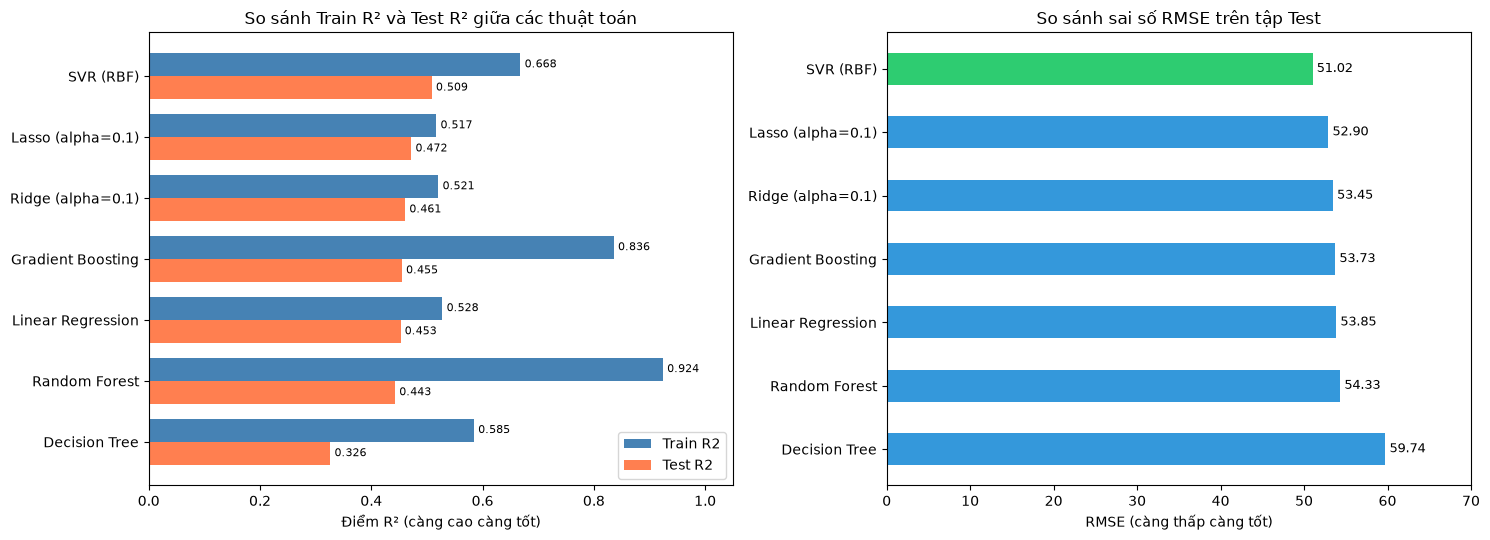

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

y_pos = np.arange(len(results_df))
height = 0.38

rects1 = axes[0].barh(y_pos - height/2, results_df['Train R2'], height, label='Train R2', color='steelblue')
rects2 = axes[0].barh(y_pos + height/2, results_df['Test R2'], height, label='Test R2', color='coral')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(results_df['Thuật toán'])
axes[0].invert_yaxis() 
axes[0].set_xlim(0, 1.05)
axes[0].set_xlabel('Điểm R² (càng cao càng tốt)')
axes[0].set_title('So sánh Train R² và Test R² giữa các thuật toán')
axes[0].legend(loc='lower right')
axes[0].bar_label(rects1, padding=3, fmt='%.3f', fontsize=8)
axes[0].bar_label(rects2, padding=3, fmt='%.3f', fontsize=8)


colors = ['#2ecc71' if i == 0 else '#3498db' for i in range(len(results_df))]
rects3 = axes[1].barh(y_pos, results_df['RMSE'], height=0.5, color=colors)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(results_df['Thuật toán'])
axes[1].invert_yaxis()
axes[1].set_xlim(0, 70)
axes[1].set_xlabel('RMSE (càng thấp càng tốt)')
axes[1].set_title('So sánh sai số RMSE trên tập Test')
axes[1].bar_label(rects3, padding=3, fmt='%.2f', fontsize=9)

plt.tight_layout()
plt.show()

### Nhận xét kết quả so sánh các thuật toán:

1. **Mô hình đạt hiệu năng cao nhất — `SVR (RBF)`:**
   * `SVR` với nhân phi tuyến RBF đạt kết quả vượt trội nhất trên tập kiểm thử với **$Test\ R^2 = 0.5087$**, **$MAE = 39.39$** và **$RMSE = 51.02$** (mô hình duy nhất vượt mốc $R^2 > 0.50$).
   * Do dữ liệu Diabetes đã được chuẩn hóa đồng nhất về cùng thang đo từ đầu, thuật toán dựa trên khoảng cách/nhân như SVR phát huy hiệu quả rất cao trong việc nắm bắt các mối quan hệ phi tuyến nhẹ.

2. **Nhóm mô hình tuyến tính có điều chuẩn (`Lasso`, `Ridge`) ổn định và ít quá khớp:**
   * Cả `Lasso (alpha=0.1)` ($Test\ R^2 = 0.4719$) và `Ridge (alpha=0.1)` ($Test\ R^2 = 0.4609$) đều cải thiện độ chính xác so với `Linear Regression` gốc ($0.4526$) nhờ kiểm soát được hiện tượng đa cộng tuyến giữa các biến xét nghiệm huyết thanh (`s1`–`s6`).
   * Khoảng cách giữa $Train\ R^2$ và $Test\ R^2$ của nhóm này rất nhỏ ($\approx 0.04 - 0.06$), chứng tỏ khả năng tổng quát hóa tốt.

3. **Hiện tượng quá khớp (Overfitting) ở nhóm mô hình cây trên tập dữ liệu nhỏ:**
   * Bộ dữ liệu Diabetes chỉ có **353 mẫu huấn luyện**, khiến các mô hình cây phức tạp dễ học thuộc nhiễu: `Random Forest` đạt $Train\ R^2$ lên tới **$0.9242$** nhưng $Test\ R^2$ tụt xuống chỉ còn **$0.4428$**; tương tự `Gradient Boosting` đạt $Train\ R^2 = 0.8359$ nhưng $Test\ R^2 = 0.4529$.
   * `Decision Tree` đơn lẻ cho kết quả kém nhất ($Test\ R^2 = 0.3264$, $RMSE = 59.74$) do phân chia không gian theo các ngưỡng bậc thang rời rạc, khó mô phỏng biến mục tiêu liên tục mượt mà.